# CBFE-ARX under a payload change

This notebook changes the arm's payload in the middle of an episode and compares the CBFE-ARX agent with and without the information constraint. It starts from the setup of `cbfe_arx_arm.ipynb` with four changes:

- the **goal prior variances are halved**: the goal standard deviations drop from 0.02 rad and 0.2 rad/s to 0.014 rad and 0.14 rad/s;
- the **prior variance of the ARX coefficients is doubled**: the nominal-simulator data now count with weight 0.15 instead of 0.3, i.e., as 90 instead of 180 observations;
- the **torque limit is doubled** from 2 to 4 N m per joint;
- the **planning horizon is doubled** from 5 to 10 steps, i.e., from 0.5 to 1 s.

With the first study's actuators, the arm with a 1.5 kg payload defeated the planner whatever its model: an agent whose prior came from a 1.5 kg simulator reached only 12–42 % of the targets. The stronger motors and the longer horizon make the heavy arm controllable, so that the payload change tests adaptation rather than feasibility. The plant now integrates four RK4 substeps per 0.05 s, which keeps its one-step error below $2 \cdot 10^{-4}$ rad at the higher speeds.

The protocol runs the four targets of the first study in rounds of 12 s. The payload is 0.5 kg in the first round and 1.5 kg from the second round on, as if the arm picked up a 1 kg object. Every target is thus scored once before and at least once after the change. The heavier payload roughly halves the joint accelerations per unit torque, so an agent that keeps its old model brakes too late. Two comparisons separate the cost of the outdated model from the cost of the heavier arm itself: a payload drop to 0 kg, and a control agent whose prior comes from a simulator with the 1.5 kg payload, on an arm that carries 1.5 kg from the start.

The two agents differ only in the multiplier $\beta$ of the information constraint $I(\Theta; y \mid u) \geq -H[p_*]$: $\beta = 0$ without the constraint, and $\beta$ from the KKT conditions with it. For these goal widths the floor $-H[p_*]$ is 6.8 nats, far above the information any action offers, so the KKT multiplier sits at $\beta_{\max} = 50$ throughout.

1. Settings
2. What the two prior changes do on the static task
3. One episode with a payload change
4. Adaptation over four rounds
5. The model learns the new dynamics slowly
6. Playground
7. Takeaways

In [1]:
import os
for var in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(var, '1')      # tiny matrices: threading only adds overhead

import sys
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'envs' / 'robot_arm.py').exists())
for path in (REPO_ROOT, REPO_ROOT / 'experiment-arm'):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from envs.robot_arm import ArmModel, ArmParams, transition
from envs.robot_arm_viz import draw_arm, plot_workspace
import reaching as R

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
VARIANTS = {'without constraint (β = 0)': 0.0, 'with constraint (KKT β)': None}
COLORS = dict(zip(VARIANTS, ('C0', 'C3')))

## 1. Settings

This notebook documents the payload study and pins its settings, `R.PAYLOAD_STUDY`: the halved goal variances, the doubled prior variance, and the doubled torque limit and horizon. The default horizon of `reaching.py` has since returned to 5 steps (`compare_agents.ipynb`), and `R.FIRST_STUDY` holds the settings of the first study. `NEW_PAYLOAD` sets the payload after the change.

In [2]:
s = R.PAYLOAD_STUDY                                # settings of this study
truth = ArmParams()
nominal = ArmModel(truth, R.ARM_CONFIG).params      # θ at the prior mean: the simulator behind the prior
NEW_PAYLOAD = 1.5                                   # [kg] payload from the second round on

for key in ('pos_std', 'vel_std', 'prior_weight', 'prior_steps', 'u_max', 'horizon', 'n_iters',
            'rk4_substeps', 'beta_max'):
    print(f'{key:>13} = {getattr(s, key):.4g}')
print(f'{"floor":>13} = {R.joint_goal(np.zeros(2), s).negative_entropy():.2f} nats')
print(f'{"payload":>13} = {truth.m_p} kg, then {NEW_PAYLOAD} kg (nominal {nominal.m_p} kg)')

      pos_std = 0.01414
      vel_std = 0.1414
 prior_weight = 0.15
  prior_steps = 600
        u_max = 4
      horizon = 10
      n_iters = 2
 rk4_substeps = 4
     beta_max = 50
        floor = 6.75 nats
      payload = 0.5 kg, then 1.5 kg (nominal 0.35 kg)


## 2. What the setting changes do

The cell adds the four changes one at a time, starting from the first study, and runs both agents with eight noise seeds on two tasks of one round each: the static task with the 0.5 kg payload and the standard prior, and the heavy arm with a 1.5 kg payload and a prior from a 1.5 kg simulator. The table reports the fraction of targets reached, the reach time, the holding error over the last second of each target and the information per step.

In [3]:
first = R.FIRST_STUDY
priors = dict(pos_std=s.pos_std, vel_std=s.vel_std, prior_weight=s.prior_weight)
actuators = dict(u_max=s.u_max, horizon=s.horizon, rk4_substeps=s.rk4_substeps)
combos = {'first study': first,
          'goal var. ÷2': replace(first, pos_std=s.pos_std, vel_std=s.vel_std),
          'prior var. ×2': replace(first, prior_weight=s.prior_weight),
          'both priors': replace(first, **priors),
          '+ torque ×2': replace(first, **priors, u_max=s.u_max, rk4_substeps=s.rk4_substeps),
          '+ horizon ×2': replace(first, **priors, horizon=s.horizon, rk4_substeps=s.rk4_substeps),
          '+ both (this study)': s}
heavy = replace(truth, m_p=NEW_PAYLOAD)
tasks = {'static, 0.5 kg': dict(),
         f'heavy, {NEW_PAYLOAD} kg, matched prior': dict(truth=heavy, nominal=replace(nominal, m_p=NEW_PAYLOAD))}
jobs, labels = [], []
for combo, sc in combos.items():
    for task, kwargs in tasks.items():
        for agent, fb in VARIANTS.items():
            for seed in range(8):
                jobs.append(dict(dict(fixed_beta=fb, seed=seed, s=sc, truth=truth), **kwargs))
                labels.append((combo, task, agent))
t0 = time.perf_counter()
episodes = R.run_many(jobs)
print(f'{len(jobs)} episodes in {time.perf_counter() - t0:.0f} s')
static = pd.DataFrame([{'settings': c, 'task': t, 'agent': a, **R.summarise(ep, job['s'])}
                       for (c, t, a), job, ep in zip(labels, jobs, episodes)])
table = static.groupby(['task', 'settings', 'agent'], sort=False)[['reached', 'reach_time', 'hold_error',
                                                                    'info_gain']]
table.mean().round(2)

224 episodes in 65 s


reached  \
task                         settings            agent                                 
static, 0.5 kg               first study         without constraint (β = 0)     1.00   
                                                 with constraint (KKT β)        1.00   
heavy, 1.5 kg, matched prior first study         without constraint (β = 0)     0.25   
                                                 with constraint (KKT β)        0.81   
static, 0.5 kg               goal var. ÷2        without constraint (β = 0)     1.00   
                                                 with constraint (KKT β)        0.97   
heavy, 1.5 kg, matched prior goal var. ÷2        without constraint (β = 0)     0.12   
                                                 with constraint (KKT β)        0.41   
static, 0.5 kg               prior var. ×2       without constraint (β = 0)     0.84   
                                                 with constraint (KKT β)        0.97   
heavy, 1.5 kg, matched prior prior var. ×2       without constraint (β = 0)     0.19   
                                                 with constraint (KKT β)        0.50   
static, 0.5 kg               both priors         without constraint (β = 0)     0.78   
                                                 with constraint (KKT β)        0.84   
heavy, 1.5 kg, matched prior both priors         without constraint (β = 0)     0.12   
                                                 with constraint (KKT β)        0.12   
static, 0.5 kg               + torque ×2         without constraint (β = 0)     0.97   
                                                 with constraint (KKT β)        1.00   
heavy, 1.5 kg, matched prior + torque ×2         without constraint (β = 0)     0.56   
                                                 with constraint (KKT β)        0.78   
static, 0.5 kg               + horizon ×2        without constraint (β = 0)     0.66   
                                                 with constraint (KKT β)        0.94   
heavy, 1.5 kg, matched prior + horizon ×2        without constraint (β = 0)     0.16   
                                                 with constraint (KKT β)        0.22   
static, 0.5 kg               + both (this study) without constraint (β = 0)     0.84   
                                                 with constraint (KKT β)        0.91   
heavy, 1.5 kg, matched prior + both (this study) without constraint (β = 0)     0.69   
                                                 with constraint (KKT β)        0.69   

                                                                             reach_time  \
task                         settings            agent                                    
static, 0.5 kg               first study         without constraint (β = 0)        1.34   
                                                 with constraint (KKT β)           1.48   
heavy, 1.5 kg, matched prior first study         without constraint (β = 0)        2.72   
                                                 with constraint (KKT β)           1.93   
static, 0.5 kg               goal var. ÷2        without constraint (β = 0)        1.40   
                                                 with constraint (KKT β)           1.43   
heavy, 1.5 kg, matched prior goal var. ÷2        without constraint (β = 0)        2.86   
                                                 with constraint (KKT β)           2.54   
static, 0.5 kg               prior var. ×2       without constraint (β = 0)        1.93   
                                                 with constraint (KKT β)           1.63   
heavy, 1.5 kg, matched prior prior var. ×2       without constraint (β = 0)        2.85   
                                                 with constraint (KKT β)           2.45   
static, 0.5 kg               both priors         without constraint (β = 0)        1.93   
                                                 with constraint (KKT β

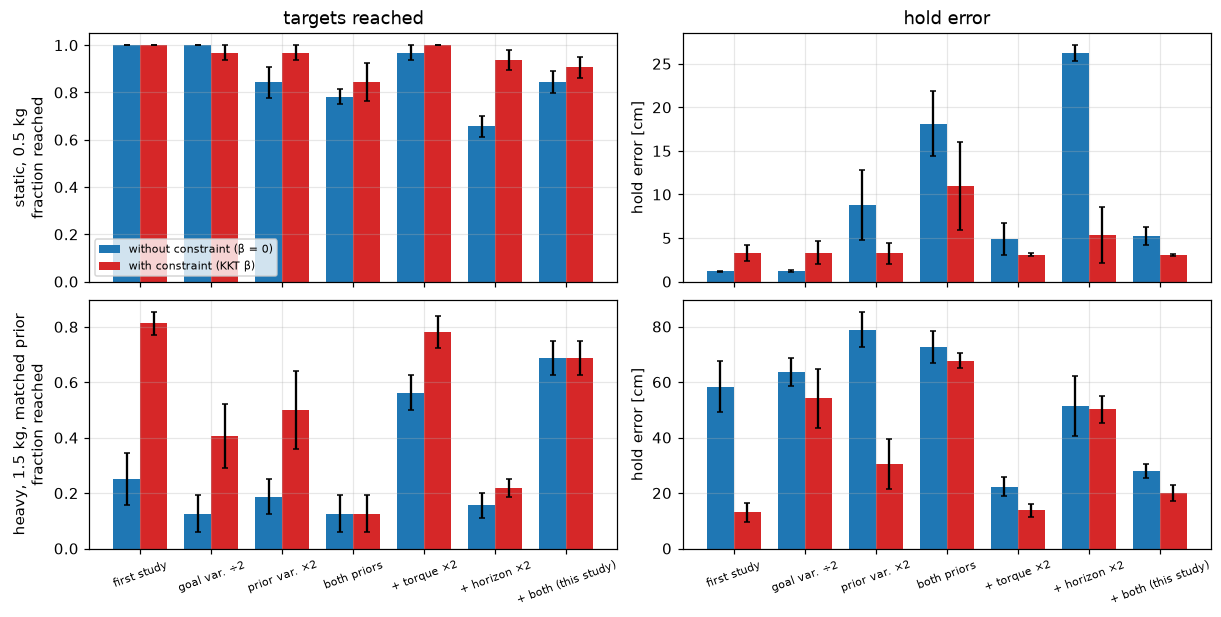

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(11, 5.5), sharex=True, layout='constrained')
x = np.arange(len(combos))
for row, task in enumerate(tasks):
    for i, agent in enumerate(VARIANTS):
        g = static[(static.task == task) & (static.agent == agent)].groupby('settings', sort=False)
        for col, metric in enumerate(('reached', 'hold_error')):
            m, se = g[metric].mean(), g[metric].sem()
            axs[row, col].bar(x + (i - 0.5) * 0.38, m, 0.38, yerr=se, color=COLORS[agent], label=agent, capsize=2)
    axs[row, 0].set(ylabel=f'{task}\nfraction reached')
    axs[row, 1].set(ylabel='hold error [cm]')
axs[0, 0].set_title('targets reached')
axs[0, 1].set_title('hold error')
for ax in axs[1]:
    ax.set_xticks(x, list(combos), fontsize=7, rotation=20)
axs[0, 0].legend(fontsize='x-small', loc='lower left')
plt.show()

The torque limit does most of the work. Doubling it on top of the new priors restores the static task, at 97–100 % of the targets held within 3–5 cm, and lifts the heavy arm with a matched prior from 12 % to 56–78 % of the targets. Doubling the horizon helps neither task. On top of the new priors alone, it lowers the static task to 66 % for the agent without the constraint and leaves the heavy arm at 16–22 %. On top of the doubled torque limit, it lowers the static task from 97–100 % to 84–91 %, moves the heavy arm to 69 % for both agents, and lengthens the reach from 1.4–1.5 s to 1.7–1.9 s.

The information constraint helps most on the heavy arm: with the first study's settings it raises the share of heavy-arm targets reached from 25 % to 81 %, and with the new priors and the doubled torque limit from 56 % to 78 %. With both doubled, as in this study, both agents reach 69 % of the heavy-arm targets and 84–91 % of the static ones.

## 3. One episode with a payload change

Both agents run two rounds with noise seed 0. The payload changes at $t = 12$ s (shaded). The lower panels show the information $I(\Theta; y \mid u)$ of the chosen actions and the response ratio of the model over a sliding window of 2 s: the realised change in joint velocity divided by the predicted change, as a least-squares slope. A ratio of 1 means a calibrated model, and a ratio below 1 means the model expects more response than the arm delivers. (Absolute prediction errors mislead here: the heavier arm accelerates less, so its errors shrink even when the model is wrong.)

without constraint (β = 0), before: reached 1.00, reach 2.30 s, hold 3.8 cm, response ratio 0.91
without constraint (β = 0),  after: reached 0.75, reach 1.70 s, hold 4.8 cm, response ratio 0.68
with constraint (KKT β), before: reached 1.00, reach 1.85 s, hold 2.9 cm, response ratio 0.91
with constraint (KKT β),  after: reached 1.00, reach 1.65 s, hold 1.9 cm, response ratio 0.69


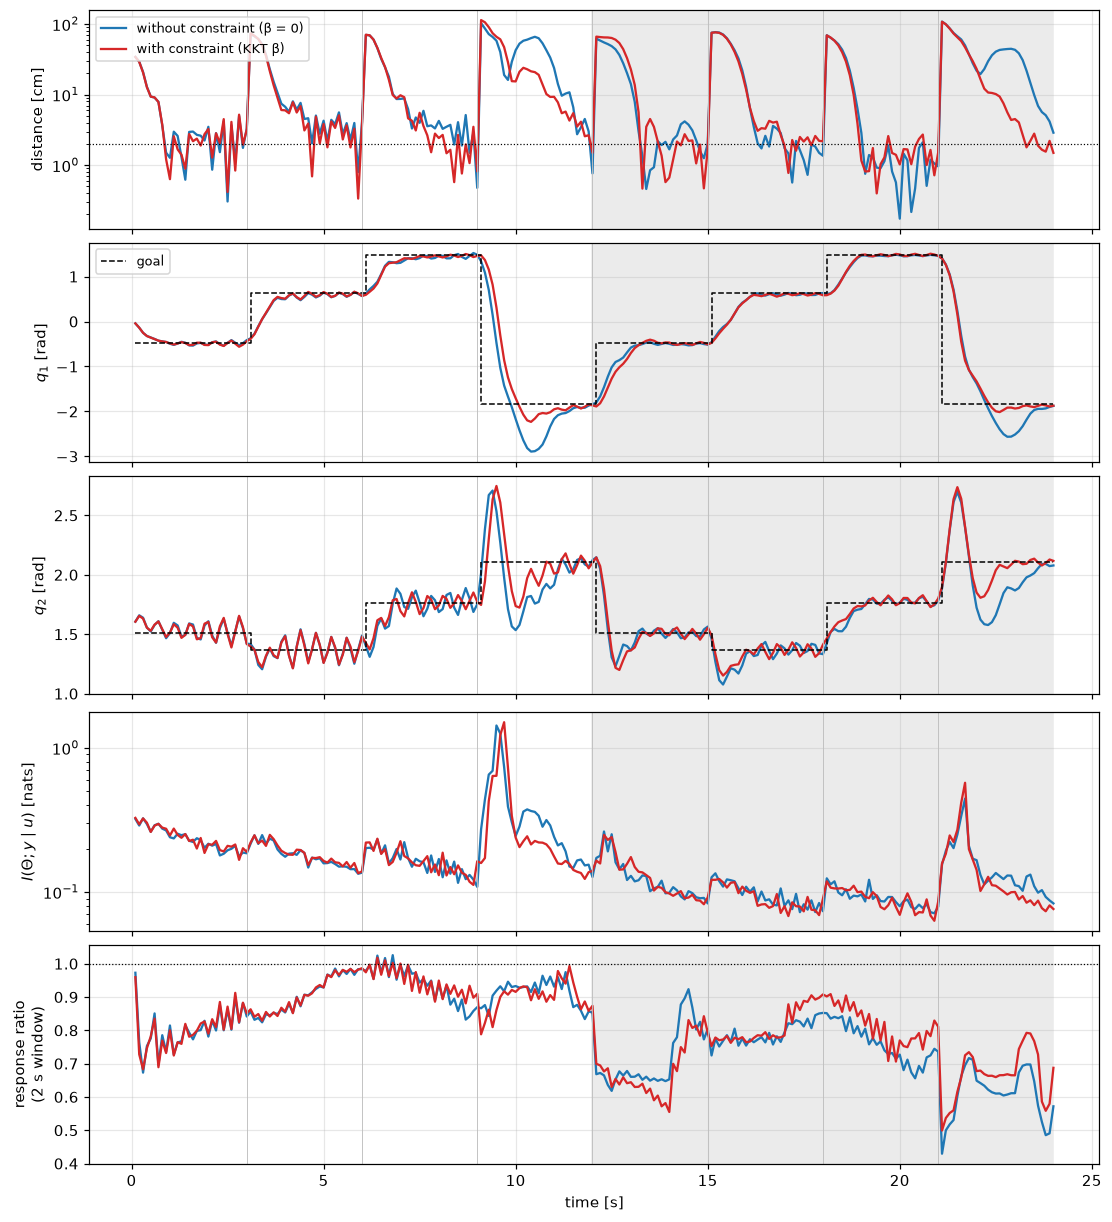

In [5]:
targets, changes = R.payload_change(NEW_PAYLOAD, s, rounds=2)
t_change = next(iter(changes)) * s.dt
pair = {label: R.run_seed(fb, seed=0, s=s, truth=truth, targets=targets, changes=changes)
        for label, fb in VARIANTS.items()}
for label, ep in pair.items():
    for name, segs in (('before', slice(0, 4)), ('after', slice(4, 8))):
        sc = R.summarise(ep, s, segs)
        print(f'{label}, {name:>6}: reached {sc["reached"]:.2f}, reach {sc["reach_time"]:.2f} s, '
              f'hold {sc["hold_error"]:.1f} cm, response ratio {sc["response_ratio"]:.2f}')

def rolling_ratio(ep, window=20):
    real, pred = ep.velocity_change
    num, den = np.sum(real * pred, axis=1), np.sum(pred * pred, axis=1)
    kernel = np.ones(window)
    return np.convolve(num, kernel)[:len(num)] / np.convolve(den, kernel)[:len(den)]

fig, axs = plt.subplots(5, 1, figsize=(10, 11), sharex=True, layout='constrained')
q_goal = R.joint_targets(next(iter(pair.values())).targets)   # goal of every step
for label, ep in pair.items():
    c = COLORS[label]
    t = np.arange(1, len(ep.actions) + 1) * ep.dt
    axs[0].plot(t, 100 * ep.distance, color=c, label=label)
    axs[1].plot(t, ep.xs[1:, 0], color=c)
    axs[2].plot(t, ep.xs[1:, 1], color=c)
    axs[3].plot(t, ep.info, color=c)
    axs[4].plot(t, rolling_ratio(ep), color=c)
axs[1].step(t, q_goal[:, 0], 'k--', lw=1, where='post', label='goal')
axs[2].step(t, q_goal[:, 1], 'k--', lw=1, where='post')
axs[0].axhline(100 * R.REACH_TOL, color='k', lw=0.8, ls=':')
axs[0].set(yscale='log', ylabel='distance [cm]')
axs[0].legend(fontsize='small', loc='upper left')
axs[1].set(ylabel='$q_1$ [rad]')
axs[1].legend(fontsize='small')
axs[2].set(ylabel='$q_2$ [rad]')
axs[3].set(ylabel=r'$I(\Theta; y \mid u)$ [nats]', yscale='log')
axs[4].axhline(1.0, color='k', lw=0.8, ls=':')
axs[4].set(ylabel='response ratio\n(2 s window)', xlabel='time [s]')
for ax in axs:
    ax.axvspan(t_change, t[-1], color='0.92', zorder=0)
    for i in range(1, len(targets)):
        ax.axvline(i * s.seconds_per_target, color='0.75', lw=0.6)
plt.show()

Both agents reach all four targets before the change. After it, the agent with the constraint reaches all four again and holds them within 1.9 cm. The agent without it misses target 4, where its shoulder overshoots to −2.6 rad; it overshot the same move before the change but recovered in time. At the change, the response ratio drops from about 0.9 to below 0.7 and recovers only partly: for most of the second round, the arm delivers 65–90 % of the velocity change the models predict, and less than half on the large move to target 4. With the stronger motors, that mismatch is no longer fatal. The information of the chosen actions again ignores the change and rises only on the large moves to target 4.

The information term cannot respond to the change, because it does not depend on the data the agent has seen, only on where it has seen them. For the matrix-normal Wishart posterior,

$$I(\Theta; y \mid u) = \frac{D_y}{2}\ln\big(1 + \ell(u)\big) + c(\nu), \qquad \ell(u) = \phi(u)^\top \Lambda^{-1} \phi(u),$$

where $\Lambda$ accumulates the features $\phi$ of past inputs and $c$ depends only on the number of observations. The prediction errors enter the posterior through $M$ and $\Omega$, and $\ln|\Omega|$ cancels between the predictive entropy and the expected likelihood entropy. A surprising output therefore changes the goal term of the policy, through $\Omega$, but not the information term.

## 4. Adaptation over four rounds

Both agents run four rounds with ten noise seeds under four conditions: the payload rises to 1.5 kg after the first round, drops to 0 kg after the first round, or stays at 0.5 kg; and, as a control, the arm carries 1.5 kg throughout while the prior comes from a simulator with the same 1.5 kg payload. The control shows what the heavy arm costs an agent whose model is right from the start. The figure shows, per round, the fraction of targets reached, the holding error and the response ratio; colours mark the condition and line styles the agent.

In [6]:
ROUNDS, N_SEEDS = 4, 10
long_targets, rise = R.payload_change(NEW_PAYLOAD, s, rounds=ROUNDS)
_, drop = R.payload_change(0.0, s, rounds=ROUNDS)
conditions = {f'rise to {NEW_PAYLOAD} kg': dict(changes=rise),
              'drop to 0 kg': dict(changes=drop),
              'no change': dict(),
              f'control: {NEW_PAYLOAD} kg throughout, matched prior':
                  dict(truth=heavy, nominal=replace(nominal, m_p=NEW_PAYLOAD))}
jobs, labels = [], []
for cond, kwargs in conditions.items():
    for agent, fb in VARIANTS.items():
        for seed in range(N_SEEDS):
            jobs.append(dict(dict(fixed_beta=fb, seed=seed, s=s, truth=truth, targets=long_targets), **kwargs))
            labels.append((cond, agent))
t0 = time.perf_counter()
long_eps = R.run_many(jobs)
print(f'{len(jobs)} episodes of {ROUNDS * 12} s in {time.perf_counter() - t0:.0f} s')
rows = []
for job, (cond, agent), ep in zip(jobs, labels, long_eps):
    for r in range(ROUNDS):
        rows.append({'condition': cond, 'agent': agent, 'round': r + 1, 'seed': job['seed'],
                     **R.summarise(ep, s, slice(4 * r, 4 * r + 4))})
rounds = pd.DataFrame(rows)
rounds.groupby(['condition', 'agent', 'round'], sort=False)[
    ['reached', 'reach_time', 'hold_error', 'response_ratio', 'info_gain']].mean().round(2)

80 episodes of 48 s in 130 s


reached  \
condition                                 agent                      round            
rise to 1.5 kg                            without constraint (β = 0) 1         0.82   
                                                                     2         0.95   
                                                                     3         0.98   
                                                                     4         0.92   
                                          with constraint (KKT β)    1         0.92   
                                                                     2         0.88   
                                                                     3         0.90   
                                                                     4         0.90   
drop to 0 kg                              without constraint (β = 0) 1         0.82   
                                                                     2         0.82   
                                                                     3         0.88   
                                                                     4         0.78   
                                          with constraint (KKT β)    1         0.92   
                                                                     2         0.80   
                                                                     3         0.72   
                                                                     4         0.80   
no change                                 without constraint (β = 0) 1         0.82   
                                                                     2         0.92   
                                                                     3         0.98   
                                                                     4         0.95   
                                          with constraint (KKT β)    1         0.92   
                                                                     2         0.95   
                                                                     3         0.98   
                                                                     4         1.00   
control: 1.5 kg throughout, matched prior without constraint (β = 0) 1         0.65   
                                                                     2         0.72   
                                                                     3         0.62   
                                                                     4         0.60   
                                          with constraint (KKT β)    1         0.68   
                                                                     2         0.75   
                                                                     3         0.60   
                                                                     4         0.72   

                                                                            reach_time  \
condition                                 agent                      round               
rise to 1.5 kg                            without constraint (β = 0) 1            1.91   
                                                                     2            1.50   
                                                                     3            1.66   
                                                                     4            1.81   
                                          with constraint (KKT β)    1            1.66   
                                                                     2            1.73   
                                                                     3            1.89   
                                                                     4            1.80   
drop to 0 kg                              without constraint (β = 0) 1            1.91   
                                                                     2            2.17   
                                     

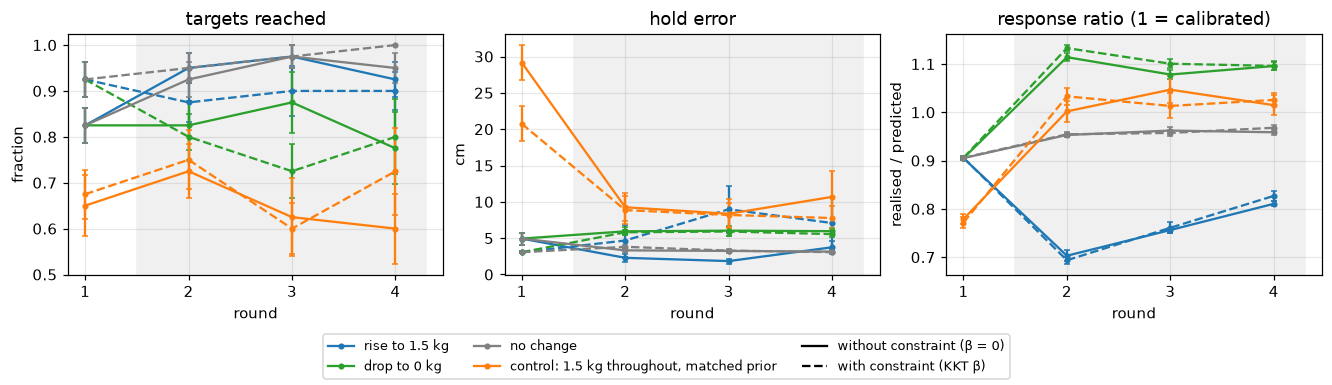

In [7]:
from matplotlib.lines import Line2D
cond_colors = dict(zip(conditions, ('C0', 'C2', '0.5', 'C1')))
agent_styles = dict(zip(VARIANTS, ('-', '--')))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), layout='constrained')
for cond in conditions:
    for agent in VARIANTS:
        g = rounds[(rounds.condition == cond) & (rounds.agent == agent)].groupby('round')
        for ax, metric in zip(axs, ('reached', 'hold_error', 'response_ratio')):
            ax.errorbar(g[metric].mean().index, g[metric].mean(), yerr=g[metric].sem(), ls=agent_styles[agent],
                        marker='o', ms=3, capsize=2, color=cond_colors[cond])
for ax, title, unit in zip(axs, ('targets reached', 'hold error', 'response ratio (1 = calibrated)'),
                           ('fraction', 'cm', 'realised / predicted')):
    ax.axvspan(1.5, ROUNDS + 0.3, color='0.94', zorder=0)
    ax.set(title=title, xlabel='round', ylabel=unit, xticks=range(1, ROUNDS + 1))
handles = ([Line2D([], [], color=c, marker='o', ms=3, label=k) for k, c in cond_colors.items()]
           + [Line2D([], [], color='k', ls=l, label=k) for k, l in agent_styles.items()])
fig.legend(handles=handles, loc='outside lower center', ncol=3, fontsize='small')
plt.show()

With the stronger motors, the rise to 1.5 kg no longer hurts. The agent without the constraint reaches 92–98 % of the targets in the rounds after the change and holds them within 2–4 cm, as well as without a change, although its model over-predicts the arm's response throughout (response ratio 0.70–0.81). The agent with the constraint reaches 88–90 % of the targets but holds them less precisely after the change, at 5–9 cm against 3–4 cm without a change.

The drop to 0 kg now costs both agents. The light arm responds 10 % more than the models predict through round 4, and the agents reach 72–88 % of the targets at about 6 cm. The control reaches 60–75 % of the targets at 8–11 cm after its first round. Its model calibrates within one round (response ratio 0.78, then 1.00–1.05), yet it reaches fewer targets than the agents that started on the light arm: for this agent, a prior simulated for the heavy arm is a worse start than the light-arm prior plus 12 s of experience. In no condition does the information constraint speed up the recalibration, since the response ratios of the two agents coincide.

## 5. The model learns the new dynamics slowly

The agent's model predicts how much a unit action accelerates each joint. The cell replays the first episode of Section 3 (without the constraint) through a fresh agent and evaluates, after every step, the predicted change in joint velocity per unit action at a reference configuration, the diagonal of the input gain. The true gains before and after the change come from the plant.

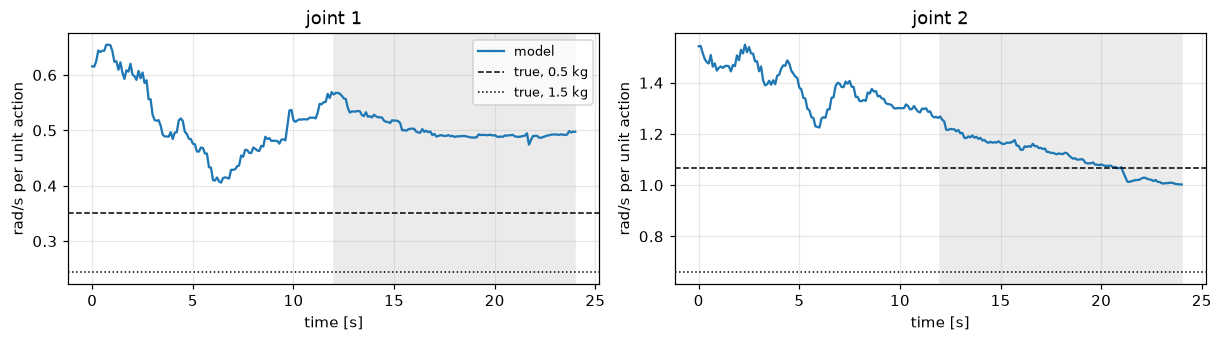

gain at the change: [0.565 1.268] | at the end: [0.497 1.003] | true after the change: [0.244 0.66 ]


In [8]:
ep = pair['without constraint (β = 0)']
q_ref = np.array([0.6, 1.4])

def true_gain(params):
    gain = np.zeros(2)
    for j in range(2):
        a = np.zeros(2)
        a[j] = 1e-3
        xp, xm = np.r_[q_ref, 0, 0], np.r_[q_ref, 0, 0]
        for _ in range(s.substeps):
            xp = transition(xp, s.u_max * a, params, R.ARM_CONFIG.dt, s.rk4_substeps)
            xm = transition(xm, -s.u_max * a, params, R.ARM_CONFIG.dt, s.rk4_substeps)
        gain[j] = (xp[j] - xm[j]) / 2e-3 / s.dt
    return gain

def model_gain(agent):
    est, gain = agent.estimator, np.zeros(2)
    for j in range(2):
        xp, xm = np.r_[0, 0, q_ref, 0, 0], np.r_[0, 0, q_ref, 0, 0]
        xp[j], xm[j] = 0.5, -0.5
        gain[j] = (est.posterior.coefficient_mean.T @ (est.feature_map(xp) - est.feature_map(xm)))[2 + j]
    return gain

agent = R.build_agent(s, 0.0, nominal, R.joint_goal(q_ref, s))
agent.estimator.output_buffer = [np.r_[ep.xs[0, :2], 0, 0]]
learned = [model_gain(agent)]
for y, a in zip(ep.ys, ep.actions):
    agent.update(y, a)
    learned.append(model_gain(agent))
learned = np.array(learned)
t = np.arange(len(learned)) * s.dt

fig, axs = plt.subplots(1, 2, figsize=(11, 3), layout='constrained')
for j, ax in enumerate(axs):
    ax.plot(t, learned[:, j], color='C0', label='model')
    for m_p, ls in ((truth.m_p, '--'), (NEW_PAYLOAD, ':')):
        ax.axhline(true_gain(replace(truth, m_p=m_p))[j], color='k', ls=ls, lw=1, label=f'true, {m_p} kg')
    ax.axvspan(t_change, t[-1], color='0.92', zorder=0)
    ax.set(title=f'joint {j + 1}', xlabel='time [s]', ylabel='rad/s per unit action')
axs[0].legend(fontsize='small')
plt.show()
print('gain at the change:', learned[int(round(t_change / s.dt))].round(3),
      '| at the end:', learned[-1].round(3),
      '| true after the change:', true_gain(replace(truth, m_p=NEW_PAYLOAD)).round(3))

With the doubled torque limit, a unit action produces twice the acceleration, so all gains are twice those of the first study. The model's elbow gain falls from 1.27 at the change to 1.00 at the end of the episode, just below the true gain before the change (1.07); the true gain after the change is 0.66. The model has one input gain for all configurations, while the true gain depends on the configuration. At the reference configuration, its shoulder gain therefore stays between 0.50 and 0.57, above both true values (0.35 and 0.24). The posterior keeps every observation at full weight and adapts as slowly as before, but with the stronger motors the agents tolerate the mismatch.

## 6. Playground

Choose the multiplier mode, the new payload, the number of rounds, the goal width factor (relative to this study), the prior weight, the torque limit, the horizon and the noise seed, then press **Run Interact**. The figure shows the end-effector distance to the targets and the joint angles, with the period after the change shaded.

In [9]:
from ipywidgets import interact_manual, widgets

@interact_manual(mode=widgets.Dropdown(options=['β = 0', 'KKT β', 'fixed β'], value='KKT β'),
                 fixed_beta=widgets.FloatLogSlider(value=10, base=10, min=-1, max=2, step=0.1),
                 new_payload=widgets.FloatSlider(value=NEW_PAYLOAD, min=0.0, max=3.0, step=0.25),
                 rounds=widgets.IntSlider(value=2, min=2, max=6),
                 goal_factor=widgets.FloatSlider(value=1.0, min=0.25, max=4.0, step=0.25),
                 prior_weight=widgets.FloatLogSlider(value=s.prior_weight, base=10, min=-2, max=0.5, step=0.1),
                 u_max=widgets.FloatSlider(value=s.u_max, min=1.0, max=6.0, step=0.5),
                 horizon=widgets.IntSlider(value=s.horizon, min=1, max=20),
                 seed=widgets.IntSlider(value=0, min=0, max=20))
def playground(mode, fixed_beta, new_payload, rounds, goal_factor, prior_weight, u_max, horizon, seed):
    sp = replace(s, pos_std=goal_factor * s.pos_std, vel_std=goal_factor * s.vel_std,
                 prior_weight=prior_weight, u_max=u_max, horizon=horizon)
    fb = {'β = 0': 0.0, 'KKT β': None, 'fixed β': fixed_beta}[mode]
    tg, ch = R.payload_change(new_payload, sp, rounds=rounds)
    ep = R.run_seed(fb, seed, sp, truth, targets=tg, changes=ch)
    for r in range(rounds):
        sc = R.summarise(ep, sp, slice(4 * r, 4 * r + 4))
        print(f'round {r + 1}: reached {sc["reached"]:.2f}, reach {sc["reach_time"]:.2f} s, '
              f'hold {sc["hold_error"]:.1f} cm, response ratio {sc["response_ratio"]:.2f}, β {sc["beta_mean"]:.1f}')
    t = np.arange(1, len(ep.actions) + 1) * ep.dt
    fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout='constrained')
    axs[0].plot(t, 100 * ep.distance, color='C3')
    axs[0].axhline(100 * R.REACH_TOL, color='k', lw=0.8, ls=':')
    axs[0].set(yscale='log', ylabel='distance [cm]')
    qg = R.joint_targets(ep.targets)
    for j in range(2):
        axs[1 + j].plot(t, ep.xs[1:, j], color='C3')
        axs[1 + j].step(t, qg[:, j], 'k--', lw=1, where='post')
        axs[1 + j].set(ylabel=f'$q_{j + 1}$ [rad]')
    for ax in axs:
        ax.axvspan(next(iter(ch)) * sp.dt, t[-1], color='0.92', zorder=0)
    axs[-1].set_xlabel('time [s]')
    plt.show()

interactive(children=(Dropdown(description='mode', index=1, options=('β = 0', 'KKT β', 'fixed β'), value='KKT …

## 7. Takeaways


- **The torque limit makes the heavy arm controllable; the horizon does not help this planner.** Doubling the torque limit lifts a matched-prior agent on the 1.5 kg arm from 12 % to 56–78 % of the targets and restores the static task to 97–100 %. Doubling the horizon as well lowers the static task to 84–91 % and lengthens the reach. With both doubled, as in this study, the agents reach 84–91 % of the static targets and 69 % of the heavy-arm targets.
- **With the stronger motors, the payload rise no longer hurts.** After the rise to 1.5 kg, the agent without the constraint performs as well as without a change (92–98 % of the targets, 2–4 cm), although its model over-predicts the arm's response throughout.
- **The payload drop now costs both agents.** They reach 72–88 % of the targets at about 6 cm, and the light arm responds 10 % more than predicted through round 4.
- **The information constraint does not speed up adaptation.** The response ratios of the two agents coincide in every condition, and after the rise the agent with the constraint holds the targets less precisely (5–9 cm against 2–4 cm).
- **The constraint helps most on the heavy arm.** It lifts the share of heavy-arm targets reached from 25 % to 81 % with the first study's settings, and from 56 % to 78 % with the new priors and the doubled torque limit. The advantage vanishes with both doubled.
- **A test of epistemic adaptation still needs an information term that sees prediction errors**, for example through a forgetting factor in the posterior or a surprise-driven multiplier.